In [1]:
import os
import numpy as np
import mne
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

from scipy.signal import butter, filtfilt
from scipy.stats import circmean

from matplotlib.gridspec import GridSpec
from sklearn.decomposition import PCA

import os

## LOAD DATA AND VISUALIZE

In [2]:
import pickle

# Load .pkl file
with open('ec013_156_preprocessed.pkl', 'rb') as f:
    data = pickle.load(f)

# Extract everything
bin_power = data['bin_power']
input_spike = data['input_spike']
bin_linear_pos = data['bin_linear_pos']
bin_head_dir = data['bin_head_dir']
bin_head_dir_binary = data['bin_head_dir_binary']
bin_speed = data['bin_speed']

fs_LFP = data['fs_LFP']
fs_pos = data['fs_pos']
duration_LFP = data['duration_LFP']
bin_size_ms = data['bin_size_ms']
bands = data['bands']


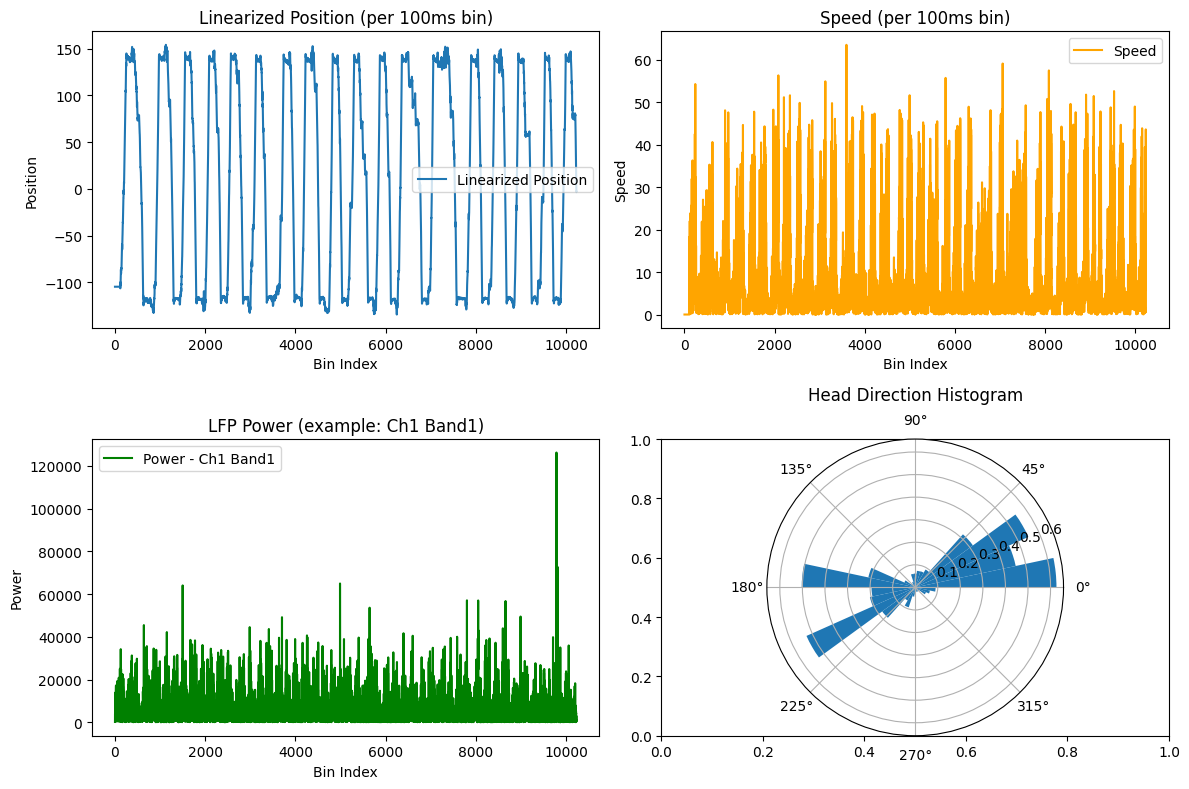

In [3]:
# Create 2x2 subplot
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

# Plot 1: Linearized position over bins
axs[0, 0].plot(bin_linear_pos, label='Linearized Position')
axs[0, 0].set_title("Linearized Position (per 100ms bin)")
axs[0, 0].set_xlabel("Bin Index")
axs[0, 0].set_ylabel("Position")
axs[0, 0].legend()

# Plot 2: Speed over bins
axs[0, 1].plot(bin_speed, label='Speed', color='orange')
axs[0, 1].set_title("Speed (per 100ms bin)")
axs[0, 1].set_xlabel("Bin Index")
axs[0, 1].set_ylabel("Speed")
axs[0, 1].legend()

# Plot 3: Power summary over time (just the first channel, first band for example)
axs[1, 0].plot(bin_power[:, 0], label='Power - Ch1 Band1', color='green')
axs[1, 0].set_title("LFP Power (example: Ch1 Band1)")
axs[1, 0].set_xlabel("Bin Index")
axs[1, 0].set_ylabel("Power")
axs[1, 0].legend()

# Plot 4: Circular histogram for head direction
axs[1, 1] = plt.subplot(2, 2, 4, polar=True)
axs[1, 1].hist(bin_head_dir, bins=30, density=True)
axs[1, 1].set_title("Head Direction Histogram", va='bottom')

plt.tight_layout()
plt.show()


## CEBRA

CEBRA does not normalize the auxiliary variables.

In [4]:
from cebra import CEBRA
import cebra.integrations.plotly
from sklearn.decomposition import PCA

In [5]:
max_iterations = 10000
LFP_output_dimension = 16
SP_output_dimension =3

In [6]:
time_color = np.arange(np.shape(bin_power)[0])
stack_aux = np.stack([bin_linear_pos,bin_speed,bin_head_dir], axis = 0)

stack_aux.shape, input_spike.shape

((3, 10235), (10235, 83))

In [7]:
input_spike = np.array(input_spike,dtype=float)

In [8]:
cebra_model1 = CEBRA(model_architecture='offset10-model',
                        batch_size=512,
                        learning_rate=3e-4,
                        temperature = 1,
                        output_dimension = LFP_output_dimension,
                        max_iterations=max_iterations,
                        distance='cosine',
                        conditional='time_delta',
                        device='cuda_if_available',
                        verbose=True,
                        time_offsets=10)


In [9]:
# cebra_model1.fit(bin_power, bin_linear_pos)
# embedding_LFP = cebra_model1.transform(bin_power)


In [10]:
# pca = PCA(n_components=10)
# embedding1= pca.fit_transform(embedding_LFP)


In [11]:
# fig = cebra.integrations.plotly.plot_embedding_interactive(embedding_LFP, embedding_labels=bin_linear_pos, title = "CEBRA-LFP-Position", cmap = "inferno")
# fig.show()

In [12]:
# cebra_model2 = CEBRA(model_architecture='offset10-model',
#                         batch_size=512,
#                         learning_rate=3e-4,
#                         temperature = 1,
#                         output_dimension = SP_output_dimension,
#                         max_iterations=max_iterations,
#                         distance='cosine',
#                         conditional='time_delta',
#                         device='cuda_if_available',
#                         verbose=True,
#                         time_offsets=10)

In [13]:
# cebra_model2.fit(input_spike, bin_linear_pos)
# embedding2 = cebra_model2.transform(input_spike)

In [14]:
# fig = cebra.integrations.plotly.plot_embedding_interactive(embedding2, embedding_labels=bin_linear_pos, title = "CEBRA-Spike-Position", cmap = "inferno")
# fig.show()

In [15]:
import ot

In [16]:
def compute_ot_distance(X, Y, reg=0.1):
    """
    Compute entropic regularized Optimal Transport (Sinkhorn) between two sets of points.

    Args:
        X (ndarray): shape (n_samples_1, n_features)
        Y (ndarray): shape (n_samples_2, n_features)
        reg (float): Regularization strength (default 0.01)

    Returns:
        gamma (ndarray): Optimal transport matrix (n_samples_1 x n_samples_2)
        distance (float): Sinkhorn transport distance
    """
    n, m = len(X), len(Y)

    # Uniform weights
    a = np.ones((n,)) / n
    b = np.ones((m,)) / m

    # Cost matrix (pairwise squared Euclidean distances)
    C = ot.dist(X, Y, metric='euclidean')**2

    # Compute entropic regularized OT (Sinkhorn)
    gamma = ot.sinkhorn(a, b, C, reg)

    # Transport cost
    distance = np.sum(gamma * C)

    return gamma, distance

In [17]:
# gamma, dist = compute_ot_distance(embedding1, embedding2)
# print(f"OT distance: {dist:.4f}")
# print(f"Gamma shape: {gamma.shape}")

In [18]:
N_parts = 4 # How many parts you want

In [19]:
# ======== Step 1: Chop data ========
n_samples = bin_power.shape[0]
samples_per_part = n_samples // N_parts

bin_power_parts = []
bin_linear_pos_parts = []
bin_head_dir_binary_parts= []
bin_speed_parts = []
input_spike_parts = []

for i in range(N_parts):
    start_idx = i * samples_per_part
    end_idx = (i + 1) * samples_per_part if i < N_parts - 1 else n_samples  # last part gets remainder

    bin_power_parts.append(bin_power[start_idx:end_idx])
    bin_linear_pos_parts.append(bin_linear_pos[start_idx:end_idx])
    bin_head_dir_binary_parts.append(bin_head_dir_binary[start_idx:end_idx])
    bin_speed_parts.append(bin_speed[start_idx:end_idx])
    input_spike_parts.append(input_spike[start_idx:end_idx])

In [20]:

# ======== Step 2: Embed each part ========
embeddings_lfp = []

for i in range(N_parts):
    X = bin_power_parts[i]
    y = bin_linear_pos_parts[i]

    cebra_model_LFP = CEBRA(model_architecture='offset10-model',
                        batch_size=512,
                        learning_rate=3e-4,
                        temperature = 1,
                        output_dimension = LFP_output_dimension,
                        max_iterations=max_iterations,
                        distance='cosine',
                        conditional='time_delta',
                        device='cuda_if_available',
                        verbose=True,
                        time_offsets=10)
    
    # --- Your embedding function here ---
    cebra_model_LFP.fit(X, y) 
    emb_temp = cebra_model_LFP.transform(X)
    pca = PCA(n_components=3)
    emb_pca= pca.fit_transform(emb_temp)

    embeddings_lfp.append(emb_pca)


pos: -0.9620 neg:  6.4991 total:  5.5371 temperature:  1.0000: 100%|██████████| 10000/10000 [01:37<00:00, 102.15it/s]
pos: -0.9635 neg:  6.5287 total:  5.5651 temperature:  1.0000: 100%|██████████| 10000/10000 [01:51<00:00, 89.83it/s]
pos: -0.9497 neg:  6.5000 total:  5.5503 temperature:  1.0000: 100%|██████████| 10000/10000 [02:04<00:00, 80.19it/s]
pos: -0.9753 neg:  6.5052 total:  5.5299 temperature:  1.0000: 100%|██████████| 10000/10000 [02:15<00:00, 73.74it/s]


In [21]:

# ======== Step 2: Embed each part ========
embeddings_spiking = []

for i in range(N_parts):
    X = input_spike_parts[i]
    y = bin_linear_pos_parts[i]

    cebra_model_SP = CEBRA(model_architecture='offset10-model',
                        batch_size=512,
                        learning_rate=3e-4,
                        temperature = 1,
                        output_dimension = SP_output_dimension,
                        max_iterations=max_iterations,
                        distance='cosine',
                        conditional='time_delta',
                        device='cuda_if_available',
                        verbose=True,
                        time_offsets=10)
    # --- Your embedding function here ---
    cebra_model_SP.fit(X, y) 
    emb_temp = cebra_model_SP.transform(X)
    embeddings_spiking.append(emb_temp)


pos: -0.9641 neg:  6.4999 total:  5.5358 temperature:  1.0000: 100%|██████████| 10000/10000 [02:17<00:00, 72.91it/s]
pos: -0.9460 neg:  6.4869 total:  5.5409 temperature:  1.0000: 100%|██████████| 10000/10000 [02:16<00:00, 73.46it/s]
pos: -0.9650 neg:  6.4987 total:  5.5337 temperature:  1.0000: 100%|██████████| 10000/10000 [02:20<00:00, 70.98it/s]
pos: -0.9656 neg:  6.5011 total:  5.5355 temperature:  1.0000: 100%|██████████| 10000/10000 [02:24<00:00, 69.01it/s]


In [22]:
embedding_dict = {
    'embeddings_spiking': embeddings_spiking,
    'embeddings_LFP': embeddings_lfp,
}

with open('ec013_156_embeddings_4.pkl', 'wb') as f:
    pickle.dump(embedding_dict, f)



In [23]:
# ======== Step 2: Embed each part ========
embeddings_lfp_shuffled = []

for i in range(N_parts):
    X = bin_power_parts[i]
    y = bin_linear_pos_parts[i]
    y_shuffled = np.random.permutation(y)
    cebra_model_LFP_shuffled = CEBRA(model_architecture='offset10-model',
                        batch_size=512,
                        learning_rate=3e-4,
                        temperature = 1,
                        output_dimension = LFP_output_dimension,
                        max_iterations=max_iterations,
                        distance='cosine',
                        conditional='time_delta',
                        device='cuda_if_available',
                        verbose=True,
                        time_offsets=10)
    
    # --- Your embedding function here ---
    cebra_model_LFP_shuffled.fit(X, y_shuffled) 
    emb_temp = cebra_model_LFP_shuffled.transform(X)
    pca = PCA(n_components=3)
    emb_pca= pca.fit_transform(emb_temp)

    embeddings_lfp_shuffled.append(emb_pca)


pos: -0.4355 neg:  6.5020 total:  6.0665 temperature:  1.0000: 100%|██████████| 10000/10000 [02:12<00:00, 75.49it/s]
pos: -0.5190 neg:  6.5684 total:  6.0494 temperature:  1.0000: 100%|██████████| 10000/10000 [02:17<00:00, 72.79it/s]
pos: -0.4558 neg:  6.4846 total:  6.0288 temperature:  1.0000: 100%|██████████| 10000/10000 [02:26<00:00, 68.29it/s]
pos: -0.4816 neg:  6.5042 total:  6.0226 temperature:  1.0000: 100%|██████████| 10000/10000 [02:25<00:00, 68.94it/s]


In [24]:

# ======== Step 2: Embed each part ========
embeddings_spiking_shuffled = []

for i in range(N_parts):
    X = input_spike_parts[i]
    y = bin_linear_pos_parts[i]
    y_shuffled = np.random.permutation(y)
    cebra_model_SP_shuffled = CEBRA(model_architecture='offset10-model',
                        batch_size=512,
                        learning_rate=3e-4,
                        temperature = 1,
                        output_dimension = SP_output_dimension,
                        max_iterations=max_iterations,
                        distance='cosine',
                        conditional='time_delta',
                        device='cuda_if_available',
                        verbose=True,
                        time_offsets=10)
    y
    # --- Your embedding function here ---
    cebra_model_SP_shuffled.fit(X, y_shuffled) 
    emb_temp = cebra_model_SP_shuffled.transform(X)
    embeddings_spiking_shuffled.append(emb_temp)


  0%|          | 0/10000 [00:00<?, ?it/s]

pos: -0.5714 neg:  6.5800 total:  6.0085 temperature:  1.0000: 100%|██████████| 10000/10000 [02:26<00:00, 68.09it/s]
pos: -0.5618 neg:  6.5819 total:  6.0200 temperature:  1.0000: 100%|██████████| 10000/10000 [02:27<00:00, 68.00it/s]
pos: -0.6028 neg:  6.6228 total:  6.0200 temperature:  1.0000: 100%|██████████| 10000/10000 [02:27<00:00, 67.99it/s]
pos: -0.5911 neg:  6.6155 total:  6.0244 temperature:  1.0000: 100%|██████████| 10000/10000 [02:30<00:00, 66.64it/s]


In [25]:
# # Load .pkl file
# with open('ec013_156_embeddings_4.pkl', 'rb') as f:
#     data = pickle.load(f)

# # Extract everything
# embeddings_spiking =  data['embeddings_spiking']
# embeddings_lfp = data['embeddings_LFP']


In [26]:
embedding_shuffled_dict = {
    'embeddings_spiking_shuffled': embeddings_spiking_shuffled,
    'embeddings_lfp_shuffled': embeddings_lfp_shuffled,
}

with open('ec013_156_embeddings_shuffled_4.pkl', 'wb') as f:
    pickle.dump(embedding_shuffled_dict, f)



In [27]:
embeddings_stack = embeddings_spiking + embeddings_lfp +  embeddings_spiking_shuffled + embeddings_lfp_shuffled

In [58]:
matrix_N = len(embeddings_stack)
# ======== Step 3: Pairwise comparisons ========
pairwise_results = np.zeros((matrix_N, matrix_N))

for i in range(matrix_N):
    for j in range(i + 1, matrix_N):
        
        emb_i = embeddings_stack[i]
        emb_j = embeddings_stack[j]

        pca = PCA(n_components=3)
        pca_emb1 = pca.fit_transform(emb_i)

        pca = PCA(n_components=3)
        pca_emb2 = pca.fit_transform(emb_j)


        # --- Your pairwise comparison function here ---
        _, dist = compute_ot_distance(pca_emb1, pca_emb2)  # <-- replace with your function
        pairwise_results[i, j] = dist
        pairwise_results[j, i] = dist  # symmetric


f:\anaconda\envs\NRMNFD\lib\site-packages\ot\bregman\_sinkhorn.py:667: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(
f:\anaconda\envs\NRMNFD\lib\site-packages\ot\bregman\_sinkhorn.py:667: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(
f:\anaconda\envs\NRMNFD\lib\site-packages\ot\bregman\_sinkhorn.py:667: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(
f:\anaconda\envs\NRMNFD\lib\site-packages\ot\bregman\_sinkhorn.py:667: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(
f:\anaconda\envs\NRMNFD\lib\site-packages\ot\bregman\_sinkhorn.py:667: U

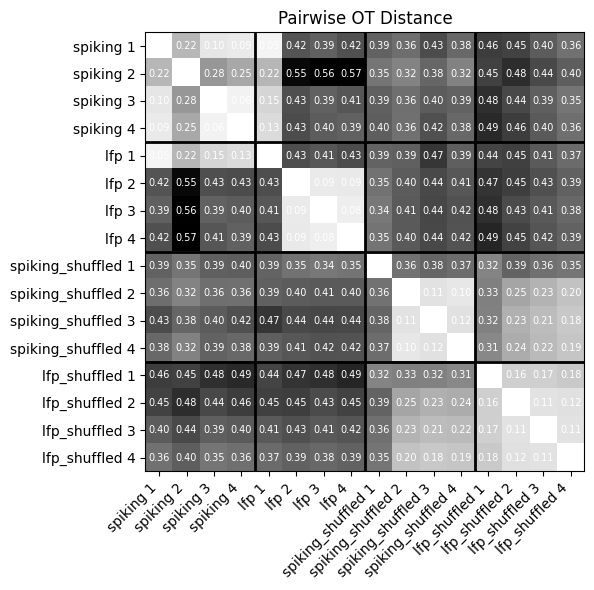

In [66]:

# ======== Plotting ========
N = 4  # number of spiking embeddings
labels = [f"spiking {i+1}" for i in range(N)] + [f"lfp {i+1}" for i in range(N)] + [f"spiking_shuffled {i+1}" for i in range(N)] + [f"lfp_shuffled {i+1}" for i in range(N)]

fig, ax = plt.subplots(figsize=(8, 6))

# Use 'plasma' colormap
im = ax.imshow(pairwise_results, cmap='Greys')

# Set ticks
ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)

# Add text annotations inside each cell
for i in range(pairwise_results.shape[0]):
    for j in range(pairwise_results.shape[1]):
        text = f"{pairwise_results[i, j]:.2f}"  # format to 2 decimal places
        ax.text(j, i, text, ha="center", va="center", color="white", fontsize=7)


# ======== Add bold lines to separate groups ========

group_size = 4  # every 4 embeddings
matrix_size = pairwise_results.shape[0]

for g in range(group_size, matrix_size, group_size):
    ax.axhline(g - 0.5, color='black', linewidth=2)
    ax.axvline(g - 0.5, color='black', linewidth=2)

# # Add colorbar
# cbar = ax.figure.colorbar(im, ax=ax)
# cbar.set_label("OT Distance")

ax.set_title("Pairwise OT Distance")
plt.tight_layout()
plt.show()

In [71]:
e1 = 4
e2 = 1

toplot_em1 = embeddings_stack[e1]
toplot_em2 = embeddings_stack[e2]

# pca = PCA(n_components=3)
# toplot_pca_emb1= pca.fit_transform(toplot_em1)

# pca = PCA(n_components=3)
# toplot_pca_emb2= pca.fit_transform(toplot_em2)


# _, test_dist = compute_ot_distance(toplot_pca_emb1, toplot_pca_emb2)

# ax1=plt.subplot(121, projection = '3d')
# ax2=plt.subplot(122, projection = '3d')

# ax1=cebra.plot_embedding(ax=ax1, embedding=toplot_em1, embedding_labels='b')
# ax2=cebra.plot_embedding(ax=ax1, embedding=toplot_em2, embedding_labels='r', title = "OT similarity = " + str(pairwise_results[e1,e2]))

# # ax3=cebra.plot_embedding(ax=ax2, embedding=toplot_pca_emb1, embedding_labels='b')
# # ax4=cebra.plot_embedding(ax=ax2, embedding=toplot_pca_emb2, embedding_labels='r', title = "OT similarity = " + str(test_dist))


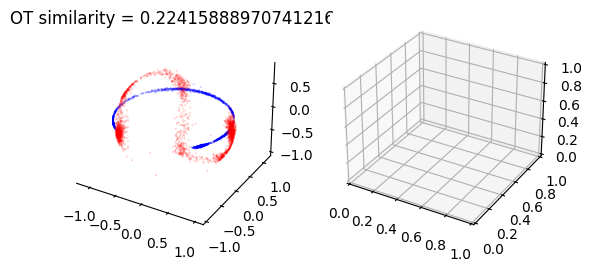

In [72]:
ax1=plt.subplot(121, projection = '3d')
ax2=plt.subplot(122, projection = '3d')

ax1=cebra.plot_embedding(ax=ax1, embedding=toplot_em1, embedding_labels='b')
ax1=cebra.plot_embedding(ax=ax1, embedding=toplot_em2, embedding_labels='r', title = "OT similarity = " + str(pairwise_results[e1,e2]))

# ax2=cebra.plot_embedding(ax=ax2, embedding=toplot_pca_emb1, embedding_labels='b')
# ax2=cebra.plot_embedding(ax=ax2, embedding=toplot_pca_emb2, embedding_labels='r', title = "OT similarity = " + str(test_dist))


In [73]:
toplot_em1.shape

(2558, 3)